# Intermediate challenge: LiH with fewer quantum resources

**Molecule:** LiH at 1.6 Å, `sto3g` basis. **Target:** stay within chemical accuracy (1.6 mHa) of the exact energy while using as few quantum resources as possible.

| Section | What it covers |
|---|---|
| 1–2 | The exact answer and the baseline (the tutorial's method, unchanged) |
| 3–5 | **Fewer qubits:** freeze core, parity mapping, tapering, active space (12 → 6 → 4 qubits) |
| 6 | Do the reductions hold at other bond lengths? |
| 7 | **Shorter circuits:** UCCSD variants vs a hardware-efficient circuit |
| 8 | **Fewer measurements:** grouping, shots per estimate, VQE with shot noise |
| 9 | Final comparison |

Shared code lives in `p1_setup.py` (molecule, reductions, circuits, resource counting) and `measure_tools.py` (shot-noise simulation). Run this notebook from the `intermediate/` folder.

In [1]:
import time; _t0 = time.time()
import warnings; warnings.filterwarnings("ignore")
import pandas as pd
from p1_setup import *

## 1. The problem and the exact answer
Every error we report is measured against this exact energy of the **full** molecule. That way, any accuracy lost by our reductions shows up honestly in the error column.

In [2]:
full = lih_problem()
E_EXACT = exact_energy(full)
print("Spatial orbitals :", full.num_spatial_orbitals)
print("Electrons (α, β) :", full.num_particles)
print("Orbital energies :", full.orbital_energies.round(3))
print(f"Exact energy     : {E_EXACT:.6f} Ha")

Spatial orbitals : 6
Electrons (α, β) : (2, 2)
Orbital energies : [-2.349 -0.285  0.078  0.164  0.164  0.548]
Exact energy     : -7.882324 Ha


## 2. Baseline: the tutorial method, unchanged
Jordan-Wigner + Hartree-Fock + UCCSD on the full problem. We record the resources but **don't run VQE** here: with 92 parameters on 12 qubits it takes far too long. That cost is exactly the problem this challenge is about.

In [3]:
results = []
p, m = reduced_lih("full")
op = m.map(p.hamiltonian.second_q_op())
row = measure_resources(build_ansatz(p, m), op, "Baseline (JW, 12q)")
row["reduced_exact_err"] = 0.0
row["vqe_err"] = None
results.append(row)
pd.DataFrame(results)

,config,qubits,params,CNOTs,depth,pauli_terms,meas_groups,reduced_exact_err,vqe_err
0,"Baseline (JW, 12q)",12,92,7520,9494,631,136,0.0,None


## 3. Reducing qubits, one trick at a time
For each step we record the resources and the **exact energy of the reduced problem**, so we can see how much accuracy each trick costs. We only run VQE on the small final candidates.

| Step | Trick | Why it's allowed |
|---|---|---|
| A | **Freeze core** | Li's 1s electrons sit far below everything else (−2.35 Ha) and barely take part in bonding |
| B | **Parity mapping** | conserving electron number lets two qubits be removed for free |
| C | **Symmetry tapering** | the molecule's mirror symmetries fix more qubit values, so those can go too |
| D | **Active space** | drop orbitals that can't take part in the bond |

In [4]:
def add(label, problem, mapper):
    op = mapper.map(problem.hamiltonian.second_q_op())
    row = measure_resources(build_ansatz(problem, mapper), op, label)
    row["reduced_exact_err"] = abs(exact_energy(problem, mapper) - E_EXACT)
    row["vqe_err"] = None
    results.append(row)
    return row

fc = FreezeCoreTransformer().transform(full)
add("A: freeze core (JW)", fc, JordanWignerMapper())
add("A+B: + parity", fc, ParityMapper(num_particles=fc.num_particles))
p6, m6 = reduced_lih("6q")
add("A+B+C: + tapering (6q)", p6, m6)
pd.DataFrame(results)

,config,qubits,params,CNOTs,depth,pauli_terms,meas_groups,reduced_exact_err,vqe_err
0,"Baseline (JW, 12q)",12,92,7520,9494,631,136,0.000000,None
1,A: freeze core (JW),10,24,1520,1939,276,58,0.000228,None
2,A+B: + parity,8,24,1212,1646,276,76,0.000228,None
3,A+B+C: + tapering (6q),6,10,304,446,231,72,0.000228,None


### Step D: choosing the active space (pick carefully!)
After freezing the core, the 5 remaining orbitals are: σ (bonding), σ\*, **π_x, π_y** (a degenerate pair), and a high σ orbital.

The obvious move is to keep the *lowest* orbitals. That keeps the π pair and throws away the high σ orbital, and it **fails**: the error is about 19 mHa, over ten times chemical accuracy.

The π orbitals point sideways, perpendicular to the Li–H bond, so by symmetry they can't mix with the σ bond. **Dropping the π pair instead** keeps the error under 1.6 mHa. This is a good point to make in the presentation.

In [5]:
naive = ActiveSpaceTransformer(num_electrons=2, num_spatial_orbitals=3).transform(fc)
add("D (naive): lowest 3 orbitals (3q)", naive,
    naive.get_tapered_mapper(ParityMapper(num_particles=naive.num_particles)))
p4, m4 = reduced_lih("4q")
add("A+B+C+D: drop π pair (4q)", p4, m4)
pd.DataFrame(results)

,config,qubits,params,CNOTs,depth,pauli_terms,meas_groups,reduced_exact_err,vqe_err
0,"Baseline (JW, 12q)",12,92,7520,9494,631,136,0.000000,None
1,A: freeze core (JW),10,24,1520,1939,276,58,0.000228,None
2,A+B: + parity,8,24,1212,1646,276,76,0.000228,None
3,A+B+C: + tapering (6q),6,10,304,446,231,72,0.000228,None
4,D (naive): lowest 3 orbitals (3q),3,4,32,70,34,13,0.019405,None
5,A+B+C+D: drop π pair (4q),4,8,172,291,100,25,0.001252,None


## 4. VQE on the reduced candidates
We run VQE on the 6- and 4-qubit versions to confirm UCCSD actually reaches the reduced problem's ground state.

In [6]:
for label, (p, m) in {"A+B+C: + tapering (6q)": (p6, m6),
                      "A+B+C+D: drop π pair (4q)": (p4, m4)}.items():
    e = run_vqe(p, m, build_ansatz(p, m))
    for r in results:
        if r["config"] == label:
            r["vqe_err"] = abs(e - E_EXACT)
    print(f"{label:28s} VQE = {e:.6f} Ha   error = {abs(e - E_EXACT)*1e3:.3f} mHa")

A+B+C: + tapering (6q)       VQE = -7.882096 Ha   error = 0.228 mHa
A+B+C+D: drop π pair (4q)    VQE = -7.881072 Ha   error = 1.252 mHa


## 5. Results table

In [7]:
df = pd.DataFrame(results)
df["within_chem_acc"] = df["reduced_exact_err"] < CHEM_ACC
df["reduced_exact_err_mHa"] = (df["reduced_exact_err"] * 1e3).round(3)
df["vqe_err_mHa"] = (df["vqe_err"].astype(float) * 1e3).round(3)
df = df.drop(columns=["reduced_exact_err", "vqe_err"])
df.to_csv("p1_results.csv", index=False)
df

,config,qubits,params,CNOTs,depth,pauli_terms,meas_groups,within_chem_acc,reduced_exact_err_mHa,vqe_err_mHa
0,"Baseline (JW, 12q)",12,92,7520,9494,631,136,True,0.000,NaN
1,A: freeze core (JW),10,24,1520,1939,276,58,True,0.228,NaN
2,A+B: + parity,8,24,1212,1646,276,76,True,0.228,NaN
3,A+B+C: + tapering (6q),6,10,304,446,231,72,True,0.228,0.228
4,D (naive): lowest 3 orbitals (3q),3,4,32,70,34,13,False,19.405,NaN
5,A+B+C+D: drop π pair (4q),4,8,172,291,100,25,True,1.252,1.252


## 6. Do the reductions hold at other bond lengths?
We compare the 6- and 4-qubit versions with the full molecule from 1.0 to 4.0 Å, using exact energies (section 4 showed VQE matches them).

In [8]:
scan = []
for d in [1.0, 1.1, 1.2, 1.3, 1.4, 1.5, 1.6, 1.8, 2.0, 2.5, 3.0, 3.5, 4.0]:
    e_full = exact_energy(lih_problem(d))
    row = {"bond_length_A": d, "E_full_Ha": e_full}
    for level in ["6q", "4q"]:
        p, m = reduced_lih(level, bond_length=d)
        e = exact_energy(p, m)
        row[f"E_{level}_Ha"] = e
        row[f"err_{level}_mHa"] = abs(e - e_full) * 1e3
    scan.append(row)
scan = pd.DataFrame(scan)
scan.to_csv("p1_bond_scan.csv", index=False)
scan.round(4)

,bond_length_A,E_full_Ha,E_6q_Ha,err_6q_mHa,E_4q_Ha,err_4q_mHa
0,1.0,-7.7845,-7.7840,0.4390,-7.7822,2.2179
1,1.1,-7.8255,-7.8252,0.3342,-7.8236,1.9377
2,1.2,-7.8524,-7.8522,0.2696,-7.8507,1.7325
3,1.3,-7.8691,-7.8689,0.2359,-7.8676,1.5767
4,1.4,-7.8785,-7.8782,0.2230,-7.8770,1.4522
5,1.5,-7.8824,-7.8821,0.2223,-7.8810,1.3466
6,1.6,-7.8823,-7.8821,0.2278,-7.8811,1.2523
7,1.8,-7.8745,-7.8743,0.2440,-7.8734,1.0837
8,2.0,-7.8611,-7.8608,0.2595,-7.8602,0.9346
9,2.5,-7.8237,-7.8234,0.2969,-7.8231,0.6472


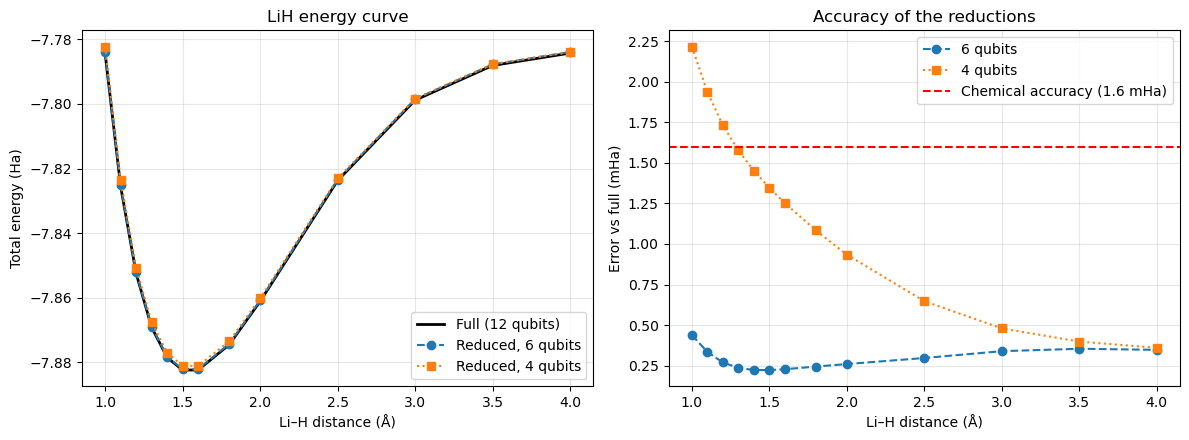

6q worst error: 0.439 mHa
4q within chemical accuracy for d ≥ 1.3 Å (worst 2.218 mHa at 1.0 Å)


In [9]:
import matplotlib.pyplot as plt
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax1.plot(scan.bond_length_A, scan.E_full_Ha, "k-", lw=2, label="Full (12 qubits)")
ax1.plot(scan.bond_length_A, scan.E_6q_Ha, "o--", label="Reduced, 6 qubits")
ax1.plot(scan.bond_length_A, scan.E_4q_Ha, "s:", label="Reduced, 4 qubits")
ax1.set(xlabel="Li–H distance (Å)", ylabel="Total energy (Ha)", title="LiH energy curve")
ax1.legend(); ax1.grid(alpha=0.3)
ax2.plot(scan.bond_length_A, scan.err_6q_mHa, "o--", label="6 qubits")
ax2.plot(scan.bond_length_A, scan.err_4q_mHa, "s:", label="4 qubits")
ax2.axhline(CHEM_ACC * 1e3, color="red", ls="--", label="Chemical accuracy (1.6 mHa)")
ax2.set(xlabel="Li–H distance (Å)", ylabel="Error vs full (mHa)", title="Accuracy of the reductions")
ax2.legend(); ax2.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f"6q worst error: {scan.err_6q_mHa.max():.3f} mHa")
print(f"4q within chemical accuracy for d ≥ {scan[scan.err_4q_mHa < 1.6].bond_length_A.min()} Å "
      f"(worst {scan.err_4q_mHa.max():.3f} mHa at {scan.bond_length_A[scan.err_4q_mHa.idxmax()]} Å)")

## 7. Shorter circuits
Same reduced problems, different circuits. We count CNOTs after compiling and run noiseless VQE.
- **UCCSD (opt 3):** the same circuit, compiled with Qiskit's heaviest optimisation.
- **Pruned UCCSD:** drop excitations whose optimal angle is tiny (|θ| < 0.01).
- **PUCCD / SUCCD:** cheaper, restricted UCC variants.
- **Hardware-efficient (EfficientSU2, 2 layers):** a generic circuit made of single-qubit rotations and a chain of CNOTs. It isn't chemistry-inspired, but it is very shallow.

In [10]:
from qiskit import transpile
from qiskit.circuit.library import efficient_su2
from qiskit_nature.second_q.circuit.library import UCC, PUCCD, SUCCD
from qiskit_algorithms.optimizers import L_BFGS_B

def cnots(circ, level=1):
    return transpile(circ, basis_gates=BASIS_GATES, optimization_level=level).count_ops().get("cx", 0)

def ucc_with(p, m, excitations):
    hf = HartreeFock(p.num_spatial_orbitals, p.num_particles, m)
    return UCC(num_spatial_orbitals=p.num_spatial_orbitals, num_particles=p.num_particles,
               excitations=lambda *a, **k: excitations, qubit_mapper=m, initial_state=hf)

def hea_vqe(p, m, op, reps, seed):
    hf = HartreeFock(p.num_spatial_orbitals, p.num_particles, m)
    a = hf.compose(efficient_su2(op.num_qubits, reps=reps, entanglement="linear"))
    v = VQE(StatevectorEstimator(), fast(a), L_BFGS_B(maxiter=1000))
    v.initial_point = np.random.default_rng(seed).uniform(-0.1, 0.1, a.num_parameters)
    return a, GroundStateEigensolver(m, v).solve(p).total_energies[0]

circuits, hea_starts = [], {}
for level, (p, m) in {"6q": (p6, m6), "4q": (p4, m4)}.items():
    op = m.map(p.hamiltonian.second_q_op())
    hf = HartreeFock(p.num_spatial_orbitals, p.num_particles, m)
    u = build_ansatz(p, m)
    theta = VQE(StatevectorEstimator(), fast(u), SLSQP()).compute_minimum_eigenvalue(op).optimal_point
    pruned = ucc_with(p, m, [e for e, t in zip(u.excitation_list, theta) if abs(t) > 0.01])
    cands = {
        "UCCSD": (u, 1),
        "UCCSD (opt 3)": (u, 3),
        "Pruned UCCSD": (pruned, 1),
        "PUCCD": (PUCCD(p.num_spatial_orbitals, p.num_particles, m, initial_state=hf), 1),
        "SUCCD": (SUCCD(p.num_spatial_orbitals, p.num_particles, m, initial_state=hf), 1),
    }
    for name, (a, opt) in cands.items():
        e = run_vqe(p, m, a)
        circuits.append({"problem": level, "circuit": name, "params": a.num_parameters,
                         "CNOTs": cnots(a, opt), "err_mHa": abs(e - E_EXACT) * 1e3})
    # hardware-efficient: 4 random starts, keep the best (and remember all of them)
    starts = [hea_vqe(p, m, op, 2, s) for s in range(4)]
    hea_starts[level] = [round((e - E_EXACT) * 1e3, 3) for _, e in starts]
    best = min(starts, key=lambda t: t[1])
    circuits.append({"problem": level, "circuit": "Hardware-efficient (2 layers)",
                     "params": best[0].num_parameters, "CNOTs": cnots(best[0]),
                     "err_mHa": abs(best[1] - E_EXACT) * 1e3})

circuits = pd.DataFrame(circuits)
circuits["chem_acc"] = circuits.err_mHa < CHEM_ACC * 1e3
circuits.to_csv("circuits_results.csv", index=False)
circuits.round(3)

,problem,circuit,params,CNOTs,err_mHa,chem_acc
0,6q,UCCSD,10,304,0.228,True
1,6q,UCCSD (opt 3),10,284,0.228,True
2,6q,Pruned UCCSD,10,304,0.228,True
3,6q,PUCCD,4,178,4.549,False
4,6q,SUCCD,5,240,2.573,False
5,6q,Hardware-efficient (2 layers),36,10,5.711,False
6,4q,UCCSD,8,172,1.252,True
7,4q,UCCSD (opt 3),8,158,1.252,True
8,4q,Pruned UCCSD,8,172,1.252,True
9,4q,PUCCD,2,80,5.750,False


In [11]:
# How reliable is the hardware-efficient circuit? Signed errors (mHa) from each of the 4 random starts.
for level, errs in hea_starts.items():
    print(level, errs)

6q [np.float64(5.712), np.float64(5.712), np.float64(5.711), np.float64(5.715)]
4q [np.float64(1.298), np.float64(1.27), np.float64(1.309), np.float64(1.27)]


**Takeaways:** on 4 qubits the hardware-efficient circuit reaches chemical accuracy with **6 CNOTs** (baseline: 1572), and does so from every random start. On 6 qubits it gets stuck at about 5.7 mHa, so UCCSD (or the pruned version) stays the right choice there. The cheaper UCC variants (PUCCD, SUCCD) miss chemical accuracy on both problems. ADAPT-VQE was also tried: it ended up keeping every UCCSD excitation, so it gave no saving here.

## 8. Fewer measurements
On real hardware the energy is estimated from a finite number of shots. `measure_tools.py` simulates this: the Hamiltonian is split into **qubit-wise commuting groups** (one measured circuit each), the shot budget per energy evaluation is split between them, and every shot is counted.

### 8a. Grouping

In [12]:
from measure_tools import ShotEstimator, measurement_groups, exact_expectation

groups = []
for level in ["full", "6q", "4q"]:
    p, m = reduced_lih(level)
    op = m.map(p.hamiltonian.second_q_op())
    groups.append({"problem": level, "qubits": op.num_qubits, "pauli_terms": len(op),
                   "qubit_wise_groups": len(op.group_commuting(qubit_wise=True)),
                   "general_commuting_groups": len(op.group_commuting(qubit_wise=False))})
pd.DataFrame(groups)

,problem,qubits,pauli_terms,qubit_wise_groups,general_commuting_groups
0,full,12,631,136,35
1,6q,6,231,72,24
2,4q,4,100,25,14


Qubit-wise grouping needs only single-qubit rotations before measuring. General commuting groups are smaller still, but each needs an extra entangling circuit to measure, which costs CNOTs.

### 8b. How many shots does one energy estimate need?
At the optimal UCCSD parameters, we repeat the shot-based estimate 30 times and look at the spread.

In [13]:
def total_shift(p, m):
    """Constant to turn the measured (electronic) energy into the total energy."""
    r = GroundStateEigensolver(m, NumPyMinimumEigensolver()).solve(p)
    return r.total_energies[0] - r.eigenvalues[0].real

noise = []
for level, (p, m) in {"6q": (p6, m6), "4q": (p4, m4)}.items():
    op = m.map(p.hamiltonian.second_q_op())
    u = build_ansatz(p, m)
    theta = VQE(StatevectorEstimator(), fast(u), SLSQP()).compute_minimum_eigenvalue(op).optimal_point
    for budget in [1e4, 1e5, 1e6]:
        est = ShotEstimator(u, op, int(budget), seed=0)
        vals = [est.energy(theta) for _ in range(30)]
        noise.append({"problem": level, "shots_per_eval": int(budget), "std_mHa": np.std(vals) * 1e3})
noise = pd.DataFrame(noise)
noise.round(3)

,problem,shots_per_eval,std_mHa
0,6q,10000,23.589
1,6q,100000,9.619
2,6q,1000000,3.135
3,4q,10000,11.480
4,4q,100000,2.751
5,4q,1000000,0.839


### 8c. VQE with shot noise
This is the hard part. We optimise using only shot-based energies, then check the **true** (noise-free) energy of the parameters it found. The optimisers are `COBYLA` and `SPSA`; SPSA is designed for noisy functions.

We use UCC with **double excitations only** (the single-excitation angles were tiny): it has fewer parameters, so there is less for the noise to confuse.

In [14]:
from qiskit_algorithms.optimizers import SPSA, COBYLA
import time

def doubles_only(p, m):
    u = build_ansatz(p, m)
    return ucc_with(p, m, [e for e in u.excitation_list if len(e[0]) == 2])

noisy = []
BUDGET = 1_000_000          # shots per energy evaluation
for level, (p, m) in {"6q": (p6, m6), "4q": (p4, m4)}.items():
    op = m.map(p.hamiltonian.second_q_op())
    a = doubles_only(p, m)
    shift = total_shift(p, m)
    noiseless_err = abs(run_vqe(p, m, a) - E_EXACT) * 1e3
    for opt_name in ["COBYLA", "SPSA"]:
        for seed in range(3):
            t = time.time()
            est = ShotEstimator(a, op, BUDGET, seed=seed)
            opt = (COBYLA(maxiter=150, rhobeg=0.05) if opt_name == "COBYLA" else
                   SPSA(maxiter=100, learning_rate=0.02, perturbation=0.02, last_avg=20))
            x = opt.minimize(est.energy, np.zeros(a.num_parameters)).x
            true_err = abs(exact_expectation(a, op, x) + shift - E_EXACT) * 1e3
            noisy.append({"problem": level, "optimizer": opt_name, "seed": seed,
                          "params": a.num_parameters, "CNOTs": cnots(a),
                          "noiseless_floor_mHa": noiseless_err, "true_err_mHa": true_err,
                          "total_shots": est.shots_used, "seconds": round(time.time() - t)})
noisy = pd.DataFrame(noisy)
noisy["chem_acc"] = noisy.true_err_mHa < CHEM_ACC * 1e3
noisy.to_csv("shots_results.csv", index=False)
noisy.round(3)

,problem,optimizer,seed,params,CNOTs,noiseless_floor_mHa,true_err_mHa,total_shots,seconds,chem_acc
0,6q,COBYLA,0,6,280,0.660,6.142,52000416,1,False
1,6q,COBYLA,1,6,280,0.660,3.015,51000408,1,False
2,6q,COBYLA,2,6,280,0.660,5.013,52000416,1,False
3,6q,SPSA,0,6,280,0.660,1.356,201001608,3,True
4,6q,SPSA,1,6,280,0.660,1.213,201001608,3,True
5,6q,SPSA,2,6,280,0.660,0.719,201001608,3,True
6,4q,COBYLA,0,4,160,1.613,2.053,38000000,0,False
7,4q,COBYLA,1,4,160,1.613,3.387,40000000,0,False
8,4q,COBYLA,2,4,160,1.613,2.396,39000000,0,False
9,4q,SPSA,0,4,160,1.613,1.639,201000000,2,False


In [15]:
noisy.groupby(["problem", "optimizer"]).agg(
    mean_err_mHa=("true_err_mHa", "mean"), worst_err_mHa=("true_err_mHa", "max"),
    runs_passing=("chem_acc", "sum"), total_shots=("total_shots", "mean")).round(3)

mean_err_mHa  worst_err_mHa  runs_passing  total_shots
problem optimizer                                                        
4q      COBYLA            2.612          3.387             0   39000000.0
        SPSA              1.720          1.860             0  201000000.0
6q      COBYLA            4.723          6.142             0   51667080.0
        SPSA              1.096          1.356             3  201001608.0

**Takeaways:**
- One estimate needs roughly 10⁵–10⁶ shots before its noise falls below 1.6 mHa.
- Under shot noise, **SPSA beats COBYLA**: COBYLA gets misled by the noise and stops early.
- **6 qubits beats 4 qubits here.** The 4-qubit model already spends about 1.3–1.6 mHa of the error budget on the reduction itself, so there's no room left for noise. The 6-qubit model spends only 0.2–0.7 mHa, which leaves room.

## 9. Final comparison

In [16]:
final = pd.DataFrame([
    {"setup": "Baseline: full JW + UCCSD", "qubits": 12, "CNOTs": 1572, "meas_groups": 136,
     "err_mHa": 0.0, "notes": "reference; too costly to even run VQE here"},
    {"setup": "6q (freeze+parity+taper) + UCCSD", "qubits": 6,
     "CNOTs": int(circuits.query("problem=='6q' and circuit=='UCCSD (opt 3)'").CNOTs.iloc[0]),
     "meas_groups": 72, "err_mHa": float(circuits.query("problem=='6q' and circuit=='UCCSD'").err_mHa.iloc[0]),
     "notes": "noiseless; accurate along the whole bond curve"},
    {"setup": "4q (+ drop π pair) + hardware-efficient", "qubits": 4,
     "CNOTs": int(circuits.query("problem=='4q' and circuit=='Hardware-efficient (2 layers)'").CNOTs.iloc[0]),
     "meas_groups": 25,
     "err_mHa": float(circuits.query("problem=='4q' and circuit=='Hardware-efficient (2 layers)'").err_mHa.iloc[0]),
     "notes": "noiseless; fewest resources; only valid for d ≥ 1.3 Å"},
    {"setup": "6q + doubles-only UCC + SPSA, with shots", "qubits": 6,
     "CNOTs": int(noisy.query("problem=='6q'").CNOTs.iloc[0]), "meas_groups": 72,
     "err_mHa": float(noisy.query("problem=='6q' and optimizer=='SPSA'").true_err_mHa.max()),
     "notes": f"worst of 3 runs; ~{noisy.query("problem=='6q' and optimizer=='SPSA'").total_shots.mean():.1e} shots"},
])
final["chem_acc"] = final.err_mHa < CHEM_ACC * 1e3
final.to_csv("final_results.csv", index=False)
final.round(3)

,setup,qubits,CNOTs,meas_groups,err_mHa,notes,chem_acc
0,Baseline: full JW + UCCSD,12,1572,136,0.000,reference; too costly to even run VQE here,True
1,6q (freeze+parity+taper) + UCCSD,6,284,72,0.228,noiseless; accurate along the whole bond curve,True
2,4q (+ drop π pair) + hardware-efficient,4,6,25,1.270,noiseless; fewest resources; only valid for d ...,True
3,"6q + doubles-only UCC + SPSA, with shots",6,280,72,1.356,worst of 3 runs; ~2.0e+08 shots,True


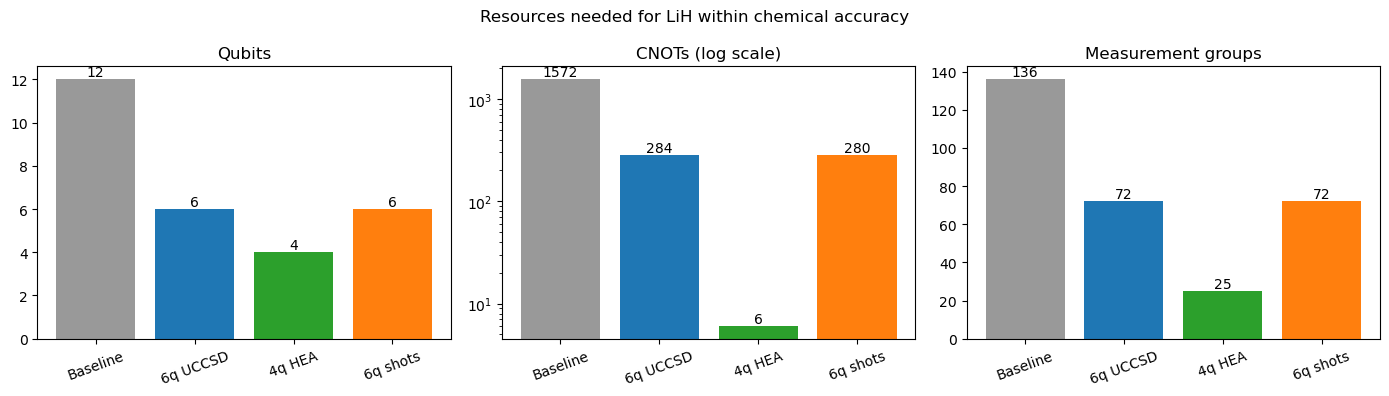

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
labels = ["Baseline", "6q UCCSD", "4q HEA", "6q shots"]
colors = ["#999999", "#1f77b4", "#2ca02c", "#ff7f0e"]
for ax, col, title, log in [(axes[0], "qubits", "Qubits", False),
                            (axes[1], "CNOTs", "CNOTs (log scale)", True),
                            (axes[2], "meas_groups", "Measurement groups", False)]:
    ax.bar(labels, final[col], color=colors)
    ax.set_title(title)
    if log: ax.set_yscale("log")
    for i, v in enumerate(final[col]): ax.text(i, v, str(v), ha="center", va="bottom")
    ax.tick_params(axis="x", rotation=20)
plt.suptitle("Resources needed for LiH within chemical accuracy")
plt.tight_layout(); plt.show()

In [18]:
print(f"Whole notebook ran in {(time.time() - _t0) / 60:.1f} minutes")

Whole notebook ran in 9.4 minutes
